# Notebook 07 — Error Analysis

## Objective
Investigate where forecasting errors occur and understand model limitations beyond overall evaluation metrics.

## Analysis Goals
Depending on the analyses implemented in the notebook:
- Compare errors across forecasting horizons.
- Examine differences across traffic sensors.
- Identify difficult prediction cases.
- Investigate whether forecast errors change as the horizon increases.

## Why Error Analysis Matters
An overall metric summarizes performance but can hide important differences between sensors, time periods, and forecasting horizons.

A model can have acceptable average performance while making larger errors in particular conditions.

## Key Concepts
- Forecast horizon: how far into the future a prediction is made.
- Residual/error: the difference between a prediction and its actual target.
- Sensor-level error: prediction error considered separately for an individual sensor.

## Review Reminder
Be prepared to explain:
- Why overall MAE may not tell the whole story.
- Why longer forecasting horizons can be more difficult.
- Which error patterns were actually observed in your notebook.
- How error analysis can guide future model improvements.

Only report specific findings that are supported by the notebook outputs.

In [1]:
from pathlib import Path

for path in [
    Path("/content/experiments/stgcn/test_predictions.npy"),
    Path("/content/experiments/stgcn/test_targets.npy"),
    Path("/content/experiments/proposed/test_predictions.npy"),
    Path("/content/experiments/proposed/test_targets.npy"),
]:
    print(path, "->", path.exists())

/content/experiments/stgcn/test_predictions.npy -> True
/content/experiments/stgcn/test_targets.npy -> True
/content/experiments/proposed/test_predictions.npy -> True
/content/experiments/proposed/test_targets.npy -> True


In [2]:
import numpy as np

stgcn_pred = np.load("/content/experiments/stgcn/test_predictions.npy")
stgcn_true = np.load("/content/experiments/stgcn/test_targets.npy")

proposed_pred = np.load("/content/experiments/proposed/test_predictions.npy")
proposed_true = np.load("/content/experiments/proposed/test_targets.npy")

print("STGCN:")
print("  Prediction:", stgcn_pred.shape)
print("  Target:    ", stgcn_true.shape)

print("\nProposed:")
print("  Prediction:", proposed_pred.shape)
print("  Target:    ", proposed_true.shape)

STGCN:
  Prediction: (6841, 3, 207, 1)
  Target:     (6841, 3, 207, 1)

Proposed:
  Prediction: (6841, 3, 207, 1)
  Target:     (6841, 3, 207, 1)


Shape validation passed.
STGCN:   (6841, 3, 207, 1)
Proposed: (6841, 3, 207, 1)

Absolute error shapes:
STGCN:    (6841, 3, 207)
Proposed: (6841, 3, 207)

Overall Absolute Error Statistics:


,STGCN,MultiScale_STGCN
Statistic,,
Mean,3.398066e-01,0.343029
Median,1.734611e-01,0.182888
Std,4.926203e-01,0.487346
Min,5.960464e-08,0.000000
Max,6.580462e+00,6.748000
P25,7.563747e-02,0.084852
P50,1.734611e-01,0.182888
P75,3.902142e-01,0.387930
P90,8.105298e-01,0.796269



Mean absolute error comparison:
STGCN:             0.339807
Multi-Scale STGCN: 0.343029
Difference:        0.003222
Relative change:   0.948%


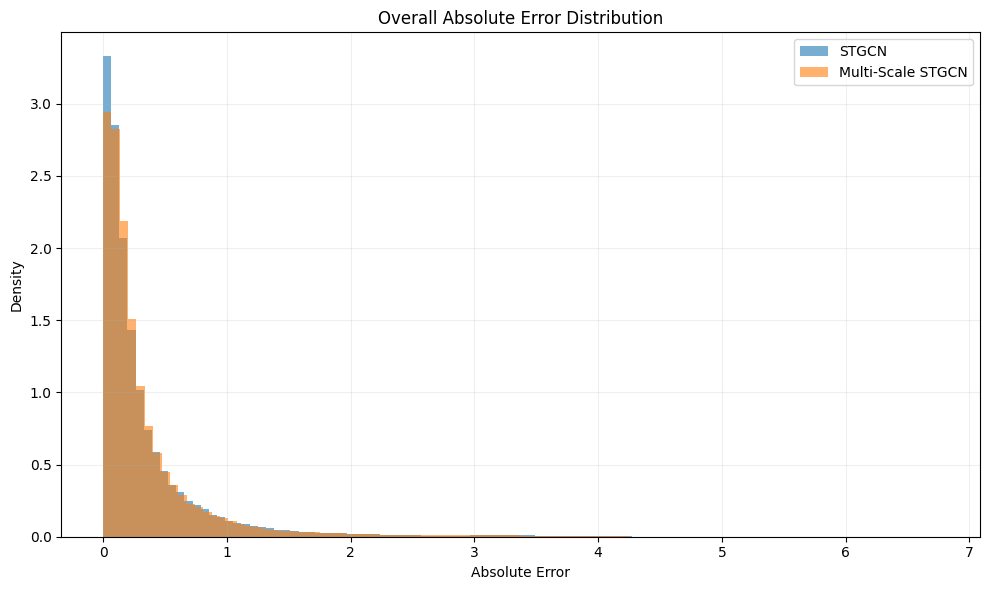

/tmp/ipykernel_24188/2501650412.py:239: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
/tmp/ipykernel_24188/2501650412.py:241: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


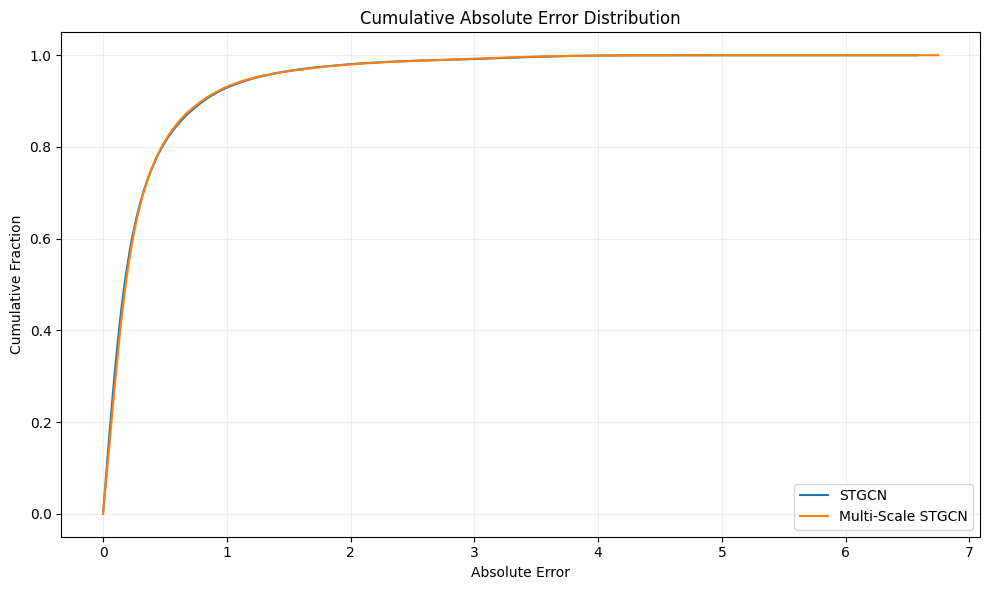


Step 1 completed.
Results saved to: /content/experiments/error_analysis
Figures saved to: /content/experiments/error_analysis/figures


In [3]:
# ============================================================
# PHASE 9 — ERROR ANALYSIS
# STEP 1 — OVERALL ERROR DISTRIBUTION
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

ERROR_ANALYSIS_DIR = Path("/content/experiments/error_analysis")
FIGURES_DIR = ERROR_ANALYSIS_DIR / "figures"

ERROR_ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 2. Load predictions and targets
# ------------------------------------------------------------

STGCN_PRED_PATH = Path(
    "/content/experiments/stgcn/test_predictions.npy"
)

STGCN_TARGET_PATH = Path(
    "/content/experiments/stgcn/test_targets.npy"
)

PROPOSED_PRED_PATH = Path(
    "/content/experiments/proposed/test_predictions.npy"
)

PROPOSED_TARGET_PATH = Path(
    "/content/experiments/proposed/test_targets.npy"
)


stgcn_pred = np.load(STGCN_PRED_PATH)
stgcn_true = np.load(STGCN_TARGET_PATH)

proposed_pred = np.load(PROPOSED_PRED_PATH)
proposed_true = np.load(PROPOSED_TARGET_PATH)


# ------------------------------------------------------------
# 3. Validate shapes
# ------------------------------------------------------------

EXPECTED_SHAPE = (6841, 3, 207, 1)

assert stgcn_pred.shape == EXPECTED_SHAPE
assert stgcn_true.shape == EXPECTED_SHAPE

assert proposed_pred.shape == EXPECTED_SHAPE
assert proposed_true.shape == EXPECTED_SHAPE

assert np.all(np.isfinite(stgcn_pred))
assert np.all(np.isfinite(stgcn_true))

assert np.all(np.isfinite(proposed_pred))
assert np.all(np.isfinite(proposed_true))


print("Shape validation passed.")
print(f"STGCN:   {stgcn_pred.shape}")
print(f"Proposed: {proposed_pred.shape}")


# ------------------------------------------------------------
# 4. Calculate absolute errors
# ------------------------------------------------------------

stgcn_abs_error = np.abs(stgcn_true - stgcn_pred)
proposed_abs_error = np.abs(proposed_true - proposed_pred)


# Remove the singleton feature dimension
stgcn_abs_error = stgcn_abs_error[..., 0]
proposed_abs_error = proposed_abs_error[..., 0]


# Shape:
# (samples, horizon, sensors)

print("\nAbsolute error shapes:")
print("STGCN:   ", stgcn_abs_error.shape)
print("Proposed:", proposed_abs_error.shape)


# ------------------------------------------------------------
# 5. Flatten errors for overall distribution
# ------------------------------------------------------------

stgcn_errors = stgcn_abs_error.reshape(-1)
proposed_errors = proposed_abs_error.reshape(-1)


# ------------------------------------------------------------
# 6. Overall error statistics
# ------------------------------------------------------------

def error_statistics(errors):
    return {
        "Mean": np.mean(errors),
        "Median": np.median(errors),
        "Std": np.std(errors),
        "Min": np.min(errors),
        "Max": np.max(errors),
        "P25": np.percentile(errors, 25),
        "P50": np.percentile(errors, 50),
        "P75": np.percentile(errors, 75),
        "P90": np.percentile(errors, 90),
        "P95": np.percentile(errors, 95),
        "P99": np.percentile(errors, 99),
    }


statistics = pd.DataFrame(
    {
        "STGCN": error_statistics(stgcn_errors),
        "MultiScale_STGCN": error_statistics(proposed_errors),
    }
)

statistics.index.name = "Statistic"


print("\nOverall Absolute Error Statistics:")
display(statistics)


# ------------------------------------------------------------
# 7. Save statistics
# ------------------------------------------------------------

statistics.to_csv(
    ERROR_ANALYSIS_DIR / "overall_error_statistics.csv"
)


# ------------------------------------------------------------
# 8. Compare mean absolute error
# ------------------------------------------------------------

mean_stgcn = np.mean(stgcn_errors)
mean_proposed = np.mean(proposed_errors)

difference = mean_proposed - mean_stgcn

if mean_stgcn != 0:
    relative_change = (difference / mean_stgcn) * 100
else:
    relative_change = np.nan


print("\nMean absolute error comparison:")
print(f"STGCN:             {mean_stgcn:.6f}")
print(f"Multi-Scale STGCN: {mean_proposed:.6f}")
print(f"Difference:        {difference:.6f}")
print(f"Relative change:   {relative_change:.3f}%")


# ------------------------------------------------------------
# 9. Plot overall error distributions
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.hist(
    stgcn_errors,
    bins=100,
    alpha=0.6,
    density=True,
    label="STGCN"
)

plt.hist(
    proposed_errors,
    bins=100,
    alpha=0.6,
    density=True,
    label="Multi-Scale STGCN"
)

plt.xlabel("Absolute Error")
plt.ylabel("Density")
plt.title("Overall Absolute Error Distribution")
plt.legend()
plt.grid(alpha=0.2)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "overall_error_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 10. Plot cumulative error distribution
# ------------------------------------------------------------

stgc_sorted = np.sort(stgcn_errors)
prop_sorted = np.sort(proposed_errors)

stgc_cdf = np.arange(1, len(stgc_sorted) + 1) / len(stgc_sorted)
prop_cdf = np.arange(1, len(prop_sorted) + 1) / len(prop_sorted)

plt.figure(figsize=(10, 6))

plt.plot(
    stgc_sorted,
    stgc_cdf,
    label="STGCN"
)

plt.plot(
    prop_sorted,
    prop_cdf,
    label="Multi-Scale STGCN"
)

plt.xlabel("Absolute Error")
plt.ylabel("Cumulative Fraction")
plt.title("Cumulative Absolute Error Distribution")
plt.legend()
plt.grid(alpha=0.2)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "cumulative_error_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


print("\nStep 1 completed.")
print(f"Results saved to: {ERROR_ANALYSIS_DIR}")
print(f"Figures saved to: {FIGURES_DIR}")

Horizon-wise error analysis:


,Horizon,STGCN_MAE,STGCN_RMSE,STGCN_Median,STGCN_P90,STGCN_P95,MultiScale_MAE,MultiScale_RMSE,MultiScale_Median,MultiScale_P90,MultiScale_P95
0,5 min,0.318080,0.552575,0.165695,0.761406,1.132376,0.315920,0.549005,0.167949,0.738038,1.112129
1,10 min,0.340512,0.599703,0.173518,0.816734,1.220408,0.345756,0.597924,0.185853,0.799824,1.207287
2,15 min,0.360828,0.639881,0.181099,0.859789,1.315557,0.367410,0.637657,0.194723,0.852589,1.309189


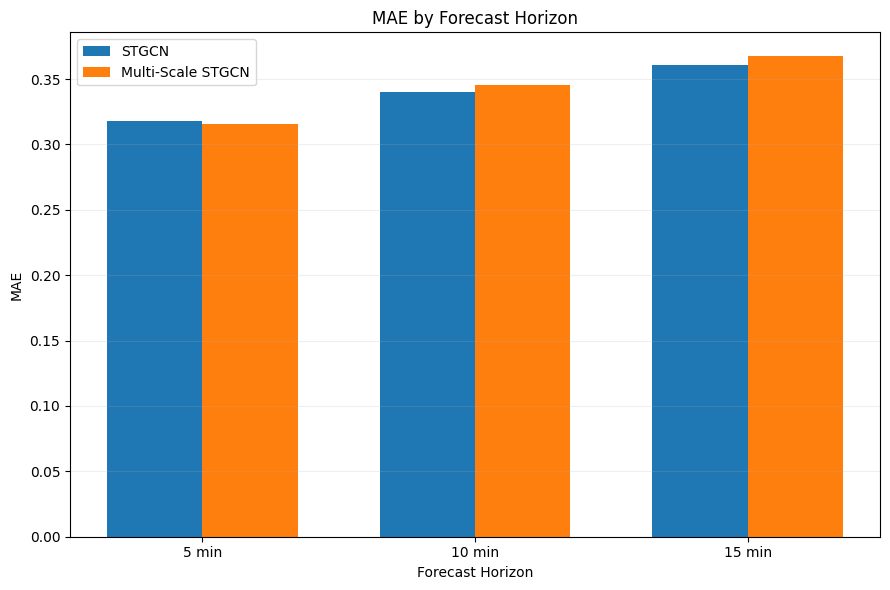

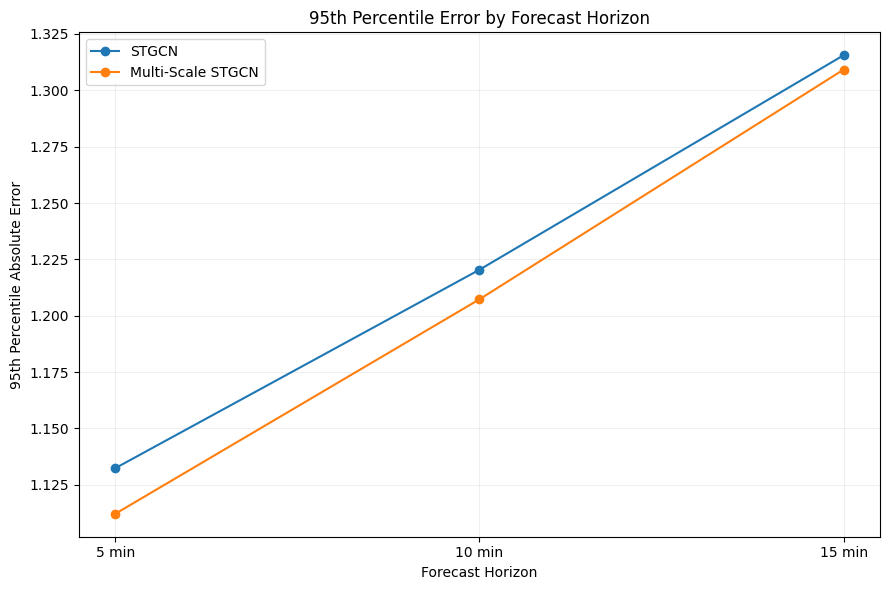


Step 2 completed.
Saved: /content/experiments/error_analysis/horizon_error_analysis.csv


In [4]:
# ============================================================
# PHASE 9 — ERROR ANALYSIS
# STEP 2 — ERROR BY FORECASTING HORIZON
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Absolute errors
# ------------------------------------------------------------

stgcn_abs_error = np.abs(stgcn_true - stgcn_pred)[..., 0]
proposed_abs_error = np.abs(proposed_true - proposed_pred)[..., 0]

# Shape:
# (samples, 3 horizons, 207 sensors)

assert stgcn_abs_error.shape == (6841, 3, 207)
assert proposed_abs_error.shape == (6841, 3, 207)


# ------------------------------------------------------------
# 2. Calculate horizon-wise statistics
# ------------------------------------------------------------

horizon_names = [
    "5 min",
    "10 min",
    "15 min"
]

rows = []

for h in range(3):

    stgcn_errors_h = stgcn_abs_error[:, h, :].reshape(-1)
    proposed_errors_h = proposed_abs_error[:, h, :].reshape(-1)

    rows.append({
        "Horizon": horizon_names[h],

        "STGCN_MAE": np.mean(stgcn_errors_h),
        "STGCN_RMSE": np.sqrt(np.mean(stgcn_errors_h ** 2)),
        "STGCN_Median": np.median(stgcn_errors_h),
        "STGCN_P90": np.percentile(stgcn_errors_h, 90),
        "STGCN_P95": np.percentile(stgcn_errors_h, 95),

        "MultiScale_MAE": np.mean(proposed_errors_h),
        "MultiScale_RMSE": np.sqrt(np.mean(proposed_errors_h ** 2)),
        "MultiScale_Median": np.median(proposed_errors_h),
        "MultiScale_P90": np.percentile(proposed_errors_h, 90),
        "MultiScale_P95": np.percentile(proposed_errors_h, 95),
    })


horizon_results = pd.DataFrame(rows)

print("Horizon-wise error analysis:")
display(horizon_results)


# ------------------------------------------------------------
# 3. Save results
# ------------------------------------------------------------

horizon_results.to_csv(
    ERROR_ANALYSIS_DIR / "horizon_error_analysis.csv",
    index=False
)


# ------------------------------------------------------------
# 4. Plot MAE by horizon
# ------------------------------------------------------------

x = np.arange(3)
width = 0.35

plt.figure(figsize=(9, 6))

plt.bar(
    x - width / 2,
    horizon_results["STGCN_MAE"],
    width,
    label="STGCN"
)

plt.bar(
    x + width / 2,
    horizon_results["MultiScale_MAE"],
    width,
    label="Multi-Scale STGCN"
)

plt.xticks(x, horizon_names)
plt.xlabel("Forecast Horizon")
plt.ylabel("MAE")
plt.title("MAE by Forecast Horizon")
plt.legend()
plt.grid(axis="y", alpha=0.2)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "horizon_mae.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 5. Plot P95 error by horizon
# ------------------------------------------------------------

plt.figure(figsize=(9, 6))

plt.plot(
    horizon_names,
    horizon_results["STGCN_P95"],
    marker="o",
    label="STGCN"
)

plt.plot(
    horizon_names,
    horizon_results["MultiScale_P95"],
    marker="o",
    label="Multi-Scale STGCN"
)

plt.xlabel("Forecast Horizon")
plt.ylabel("95th Percentile Absolute Error")
plt.title("95th Percentile Error by Forecast Horizon")
plt.legend()
plt.grid(alpha=0.2)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "horizon_p95_error.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


print("\nStep 2 completed.")
print(
    f"Saved: {ERROR_ANALYSIS_DIR / 'horizon_error_analysis.csv'}"
)

Mean shape: (207,)
Std shape: (207,)
Original-scale conversion successful.
Ground-truth range: -3.8146973e-06 to 70.0
Traffic values shape: (6841, 3, 207)
33rd percentile: 55.8889
66th percentile: 64.6667

Observation counts:
Low:    1416984
Medium: 1421758
High:   1409519


,Traffic Regime,STGCN_MAE,STGCN_RMSE,STGCN_Median,STGCN_P90,STGCN_P95,MultiScale_MAE,MultiScale_RMSE,MultiScale_Median,MultiScale_P90,MultiScale_P95,Count
0,Low traffic,10.258709,15.378609,6.699697,23.116104,33.431557,10.259614,15.377776,6.719854,23.268673,33.633778,1416984
1,Medium traffic,4.358673,7.945494,2.404028,9.282307,15.268373,4.352656,7.792183,2.504593,9.136339,14.786600,1421758
2,High traffic,4.167900,8.025511,2.255966,8.585938,14.320335,4.328741,7.889956,2.621376,8.504688,13.361197,1409519


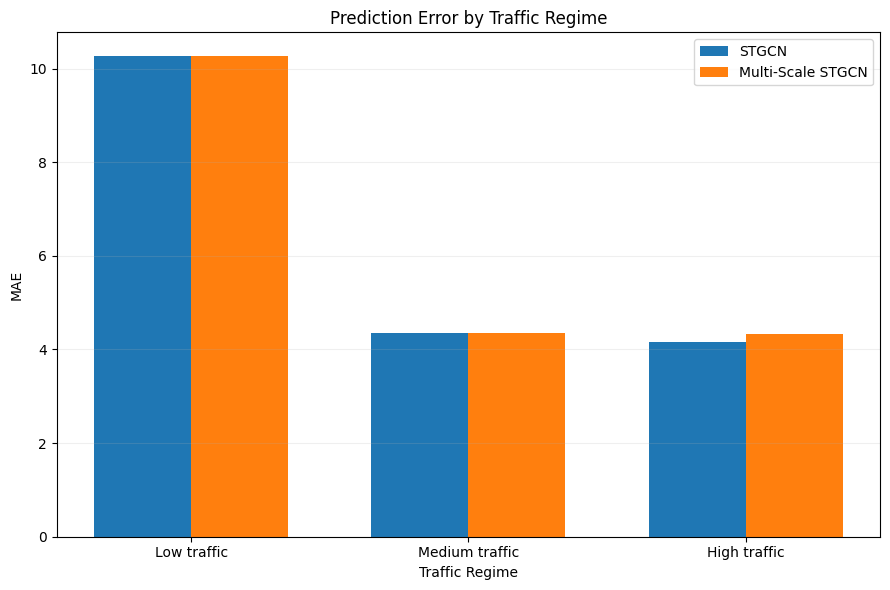


Step 3 completed.


In [5]:
# ============================================================
# PHASE 9 — ERROR ANALYSIS
# STEP 3 — ERROR BY TRAFFIC REGIME
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Load scaler
# ------------------------------------------------------------

SCALER_PATH = Path("/content/data/processed/METR-LA/scaler.npz")

scaler = np.load(SCALER_PATH)

mean = scaler["mean"].astype(np.float32)
std = scaler["std"].astype(np.float32)

print("Mean shape:", mean.shape)
print("Std shape:", std.shape)


# ------------------------------------------------------------
# 2. Inverse transform predictions and targets
# ------------------------------------------------------------

def inverse_transform(data, mean, std):

    data = np.asarray(data)

    mean = mean.reshape(1, 1, -1, 1)
    std = std.reshape(1, 1, -1, 1)

    return data * std + mean


stgcn_true_original = inverse_transform(
    stgcn_true,
    mean,
    std
)

stgcn_pred_original = inverse_transform(
    stgcn_pred,
    mean,
    std
)

proposed_true_original = inverse_transform(
    proposed_true,
    mean,
    std
)

proposed_pred_original = inverse_transform(
    proposed_pred,
    mean,
    std
)


# ------------------------------------------------------------
# 3. Verify
# ------------------------------------------------------------

assert stgcn_true_original.shape == (6841, 3, 207, 1)
assert proposed_true_original.shape == (6841, 3, 207, 1)

assert np.all(np.isfinite(stgcn_true_original))
assert np.all(np.isfinite(proposed_true_original))

print("Original-scale conversion successful.")

print(
    "Ground-truth range:",
    np.min(stgcn_true_original),
    "to",
    np.max(stgcn_true_original)
)


# ------------------------------------------------------------
# 4. Calculate absolute errors
# ------------------------------------------------------------

stgcn_error_original = np.abs(
    stgcn_true_original - stgcn_pred_original
)[..., 0]

proposed_error_original = np.abs(
    proposed_true_original - proposed_pred_original
)[..., 0]


# ------------------------------------------------------------
# 5. Ground-truth traffic values
# ------------------------------------------------------------

traffic_values = stgcn_true_original[..., 0]

print("Traffic values shape:", traffic_values.shape)


# ------------------------------------------------------------
# 6. Define traffic regimes using percentiles
# ------------------------------------------------------------

p33 = np.percentile(traffic_values, 33.333333)
p66 = np.percentile(traffic_values, 66.666667)

print(f"33rd percentile: {p33:.4f}")
print(f"66th percentile: {p66:.4f}")


# ------------------------------------------------------------
# 7. Assign each observation to a regime
# ------------------------------------------------------------

low_mask = traffic_values <= p33

medium_mask = (
    (traffic_values > p33) &
    (traffic_values <= p66)
)

high_mask = traffic_values > p66


print("\nObservation counts:")
print("Low:   ", np.sum(low_mask))
print("Medium:", np.sum(medium_mask))
print("High:  ", np.sum(high_mask))


# ------------------------------------------------------------
# 8. Calculate regime-wise statistics
# ------------------------------------------------------------

regimes = {
    "Low traffic": low_mask,
    "Medium traffic": medium_mask,
    "High traffic": high_mask,
}

rows = []

for regime_name, mask in regimes.items():

    stgcn_errors = stgcn_error_original[mask]
    proposed_errors = proposed_error_original[mask]

    rows.append({
        "Traffic Regime": regime_name,

        "STGCN_MAE": np.mean(stgcn_errors),
        "STGCN_RMSE": np.sqrt(np.mean(stgcn_errors ** 2)),
        "STGCN_Median": np.median(stgcn_errors),
        "STGCN_P90": np.percentile(stgcn_errors, 90),
        "STGCN_P95": np.percentile(stgcn_errors, 95),

        "MultiScale_MAE": np.mean(proposed_errors),
        "MultiScale_RMSE": np.sqrt(np.mean(proposed_errors ** 2)),
        "MultiScale_Median": np.median(proposed_errors),
        "MultiScale_P90": np.percentile(proposed_errors, 90),
        "MultiScale_P95": np.percentile(proposed_errors, 95),

        "Count": len(stgcn_errors),
    })


traffic_results = pd.DataFrame(rows)

display(traffic_results)


# ------------------------------------------------------------
# 9. Save results
# ------------------------------------------------------------

traffic_results.to_csv(
    ERROR_ANALYSIS_DIR / "traffic_regime_error_analysis.csv",
    index=False
)


# ------------------------------------------------------------
# 10. Plot MAE by traffic regime
# ------------------------------------------------------------

x = np.arange(3)
width = 0.35

plt.figure(figsize=(9, 6))

plt.bar(
    x - width / 2,
    traffic_results["STGCN_MAE"],
    width,
    label="STGCN"
)

plt.bar(
    x + width / 2,
    traffic_results["MultiScale_MAE"],
    width,
    label="Multi-Scale STGCN"
)

plt.xticks(
    x,
    traffic_results["Traffic Regime"]
)

plt.xlabel("Traffic Regime")
plt.ylabel("MAE")
plt.title("Prediction Error by Traffic Regime")

plt.legend()
plt.grid(axis="y", alpha=0.2)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "traffic_regime_mae.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


print("\nStep 3 completed.")

33rd percentile: 59.3750
66th percentile: 65.2500


,Traffic Regime,STGCN_MAPE,STGCN_Median_APE,STGCN_P90_APE,STGCN_P95_APE,MultiScale_MAPE,MultiScale_Median_APE,MultiScale_P90_APE,MultiScale_P95_APE,Count
0,Low traffic,26.436118,11.498671,65.990356,98.711601,25.934083,11.087918,65.867255,97.685310,1249085
1,Medium traffic,6.753826,3.650330,14.399782,23.973370,6.835658,3.897904,14.293443,23.345142,1241709
2,High traffic,6.175718,3.344329,12.661126,21.190039,6.416733,3.906715,12.525527,19.660978,1242304


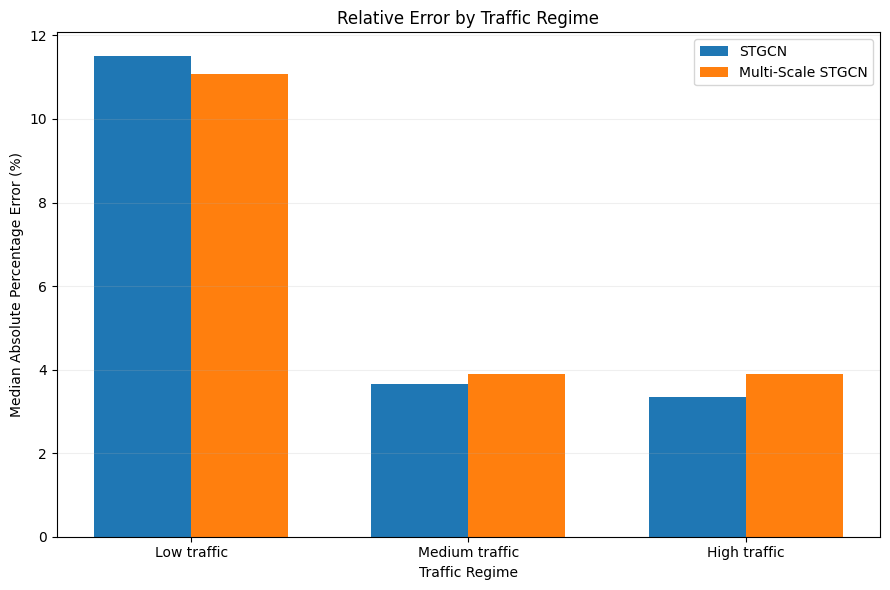


Step 4 completed.


In [6]:
# ============================================================
# PHASE 9 — ERROR ANALYSIS
# STEP 4 — RELATIVE ERROR BY TRAFFIC REGIME
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Ground-truth traffic
# ------------------------------------------------------------

traffic_values = stgcn_true_original[..., 0]

# ------------------------------------------------------------
# 2. Absolute errors
# ------------------------------------------------------------

stgcn_abs_error = np.abs(
    stgcn_true_original - stgcn_pred_original
)[..., 0]

proposed_abs_error = np.abs(
    proposed_true_original - proposed_pred_original
)[..., 0]


# ------------------------------------------------------------
# 3. Safe relative error
# ------------------------------------------------------------
#
# Avoid unstable percentage errors when traffic is near zero.
#
# We use a small denominator threshold based on the observed
# traffic distribution.

epsilon = 1.0

valid_mask = traffic_values > epsilon

stgcn_relative_error = np.full_like(
    stgcn_abs_error,
    np.nan,
    dtype=np.float64
)

proposed_relative_error = np.full_like(
    proposed_abs_error,
    np.nan,
    dtype=np.float64
)

stgcn_relative_error[valid_mask] = (
    stgcn_abs_error[valid_mask]
    / traffic_values[valid_mask]
) * 100.0

proposed_relative_error[valid_mask] = (
    proposed_abs_error[valid_mask]
    / traffic_values[valid_mask]
) * 100.0


# ------------------------------------------------------------
# 4. Traffic regimes
# ------------------------------------------------------------

valid_traffic = traffic_values[valid_mask]

p33 = np.percentile(valid_traffic, 33.333333)
p66 = np.percentile(valid_traffic, 66.666667)

print(f"33rd percentile: {p33:.4f}")
print(f"66th percentile: {p66:.4f}")


low_mask = valid_mask & (traffic_values <= p33)

medium_mask = (
    valid_mask
    & (traffic_values > p33)
    & (traffic_values <= p66)
)

high_mask = valid_mask & (traffic_values > p66)


regimes = {
    "Low traffic": low_mask,
    "Medium traffic": medium_mask,
    "High traffic": high_mask,
}


# ------------------------------------------------------------
# 5. Calculate relative-error statistics
# ------------------------------------------------------------

rows = []

for regime_name, mask in regimes.items():

    stgcn_errors = stgcn_relative_error[mask]
    proposed_errors = proposed_relative_error[mask]

    stgcn_errors = stgcn_errors[np.isfinite(stgcn_errors)]
    proposed_errors = proposed_errors[np.isfinite(proposed_errors)]

    rows.append({
        "Traffic Regime": regime_name,

        "STGCN_MAPE": np.mean(stgcn_errors),
        "STGCN_Median_APE": np.median(stgcn_errors),
        "STGCN_P90_APE": np.percentile(stgcn_errors, 90),
        "STGCN_P95_APE": np.percentile(stgcn_errors, 95),

        "MultiScale_MAPE": np.mean(proposed_errors),
        "MultiScale_Median_APE": np.median(proposed_errors),
        "MultiScale_P90_APE": np.percentile(proposed_errors, 90),
        "MultiScale_P95_APE": np.percentile(proposed_errors, 95),

        "Count": len(stgcn_errors),
    })


relative_results = pd.DataFrame(rows)

display(relative_results)


# ------------------------------------------------------------
# 6. Save
# ------------------------------------------------------------

relative_results.to_csv(
    ERROR_ANALYSIS_DIR / "traffic_regime_relative_error.csv",
    index=False
)


# ------------------------------------------------------------
# 7. Plot median absolute percentage error
# ------------------------------------------------------------

x = np.arange(3)
width = 0.35

plt.figure(figsize=(9, 6))

plt.bar(
    x - width / 2,
    relative_results["STGCN_Median_APE"],
    width,
    label="STGCN"
)

plt.bar(
    x + width / 2,
    relative_results["MultiScale_Median_APE"],
    width,
    label="Multi-Scale STGCN"
)

plt.xticks(
    x,
    relative_results["Traffic Regime"]
)

plt.xlabel("Traffic Regime")
plt.ylabel("Median Absolute Percentage Error (%)")
plt.title("Relative Error by Traffic Regime")

plt.legend()
plt.grid(axis="y", alpha=0.2)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "traffic_regime_relative_error.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


print("\nStep 4 completed.")

Sensor-level results:


,Sensor,STGCN_MAE,STGCN_RMSE,STGCN_Median,STGCN_P90,STGCN_P95,MultiScale_MAE,MultiScale_RMSE,MultiScale_Median,MultiScale_P90,MultiScale_P95
0,0,4.480777,9.537444,1.967934,10.506635,19.051239,4.875694,9.813471,2.329529,11.964979,19.884298
1,1,3.511676,7.843167,1.393318,10.276730,12.636105,3.614265,7.883005,1.527565,11.107376,13.552704
2,2,4.053345,8.673180,2.153893,6.708921,15.930464,4.495427,8.867127,2.639862,6.206101,16.703087
3,3,4.982591,7.816991,3.739052,9.110806,12.950640,5.036180,7.808170,3.680202,9.411866,12.871780
4,4,8.277637,12.062044,6.319412,14.806663,21.944546,8.338134,11.993576,6.428364,14.889639,21.805157



Top 15 highest-error sensors — STGCN


,Sensor,STGCN_MAE,STGCN_RMSE,STGCN_Median,STGCN_P90,STGCN_P95
77,77,15.956015,22.161585,8.683357,37.849426,47.217888
38,38,14.779117,19.008482,11.217106,29.803761,36.425774
82,82,13.959284,20.608686,6.707588,39.935764,44.601524
71,71,13.260199,20.987654,4.605839,40.763756,45.583111
47,47,12.985489,19.872364,5.440826,40.997665,44.385063
75,75,12.863876,21.528479,4.149567,48.081051,51.336079
12,12,12.751573,15.619600,10.444344,28.232927,29.544987
105,105,12.471081,17.928095,7.508190,32.120922,37.186447
160,160,12.268071,18.022236,7.153141,27.196390,45.322678
70,70,11.833672,19.545401,3.481312,37.529140,43.030083



Top 15 highest-error sensors — Multi-Scale STGCN


,Sensor,MultiScale_MAE,MultiScale_RMSE,MultiScale_Median,MultiScale_P90,MultiScale_P95
38,38,14.984863,18.842417,12.064415,28.942289,36.026596
82,82,14.526134,21.076622,7.087448,40.723198,43.525707
77,77,14.025944,20.498405,7.809380,34.892780,51.647221
105,105,13.254040,18.625528,8.418949,30.588116,47.928551
71,71,13.034159,20.482029,4.755733,39.250954,45.331760
47,47,12.634595,19.214327,5.465157,39.571030,42.720329
12,12,12.477510,15.302329,10.572664,27.037968,28.544155
75,75,12.155082,19.848713,4.339420,43.891182,46.180157
160,160,11.980418,17.612120,6.896585,27.285667,45.977425
70,70,11.666016,19.197205,3.522179,33.783154,43.842304


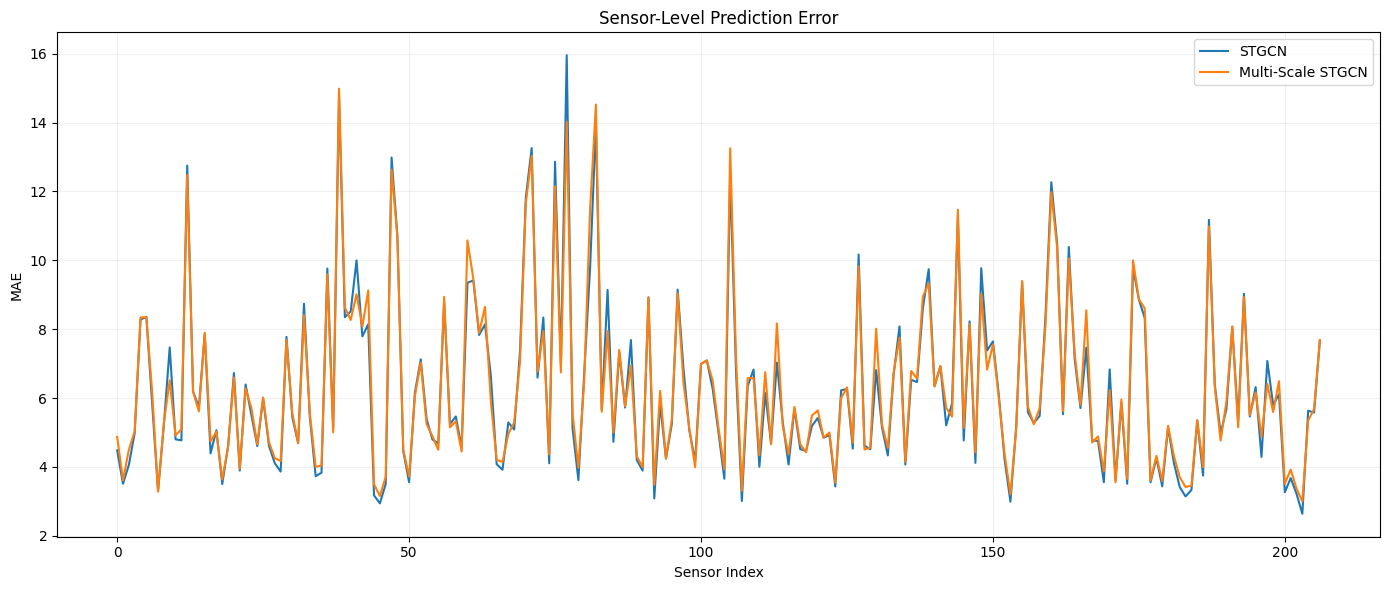

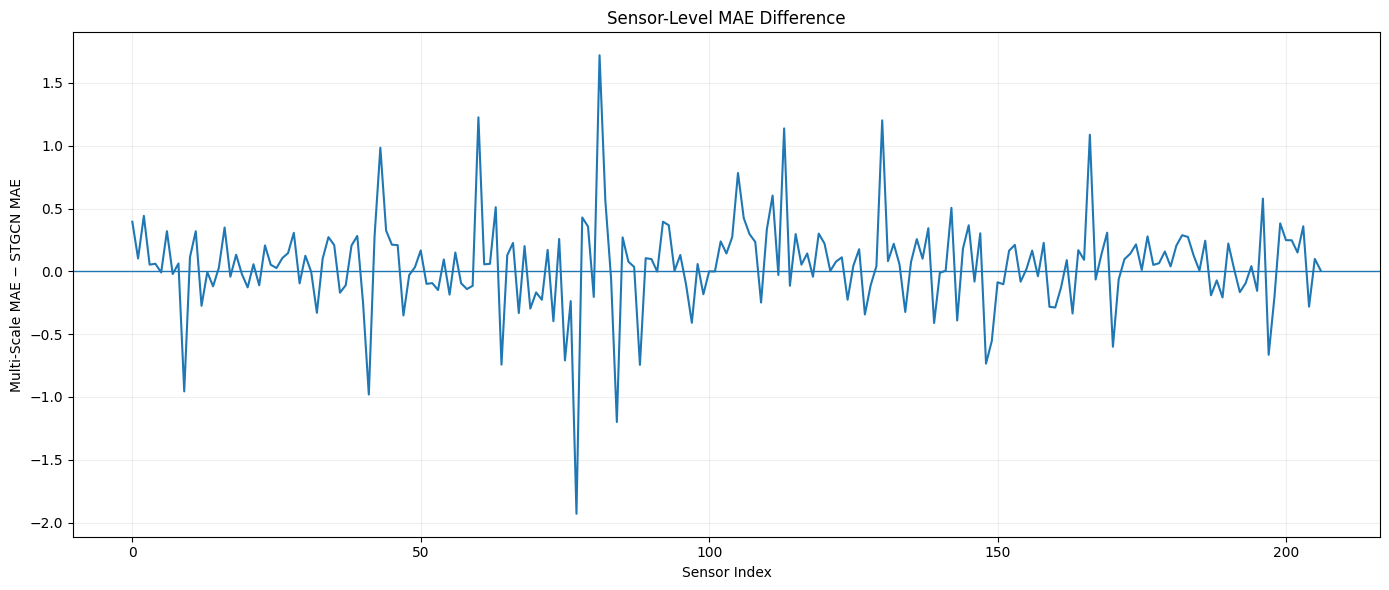


Sensor-level comparison
--------------------------------
STGCN lower MAE:        129
Multi-Scale lower MAE:  78
Equal:                   0
Total sensors:           207

Step 5 completed.


In [7]:
# ============================================================
# PHASE 9 — ERROR ANALYSIS
# STEP 5 — SENSOR-LEVEL SPATIAL ERROR ANALYSIS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Verify original-scale arrays
# ------------------------------------------------------------

assert stgcn_true_original.shape == (6841, 3, 207, 1)
assert stgcn_pred_original.shape == (6841, 3, 207, 1)

assert proposed_true_original.shape == (6841, 3, 207, 1)
assert proposed_pred_original.shape == (6841, 3, 207, 1)


# ------------------------------------------------------------
# 2. Remove final feature dimension
# ------------------------------------------------------------

stgcn_error = np.abs(
    stgcn_true_original - stgcn_pred_original
)[..., 0]

proposed_error = np.abs(
    proposed_true_original - proposed_pred_original
)[..., 0]

# Shape:
# (6841 samples, 3 horizons, 207 sensors)

assert stgcn_error.shape == (6841, 3, 207)
assert proposed_error.shape == (6841, 3, 207)


# ------------------------------------------------------------
# 3. Calculate sensor-level statistics
# ------------------------------------------------------------

sensor_rows = []

for sensor in range(207):

    stgcn_sensor_error = stgcn_error[:, :, sensor].reshape(-1)
    proposed_sensor_error = proposed_error[:, :, sensor].reshape(-1)

    sensor_rows.append({

        "Sensor": sensor,

        "STGCN_MAE": np.mean(stgcn_sensor_error),
        "STGCN_RMSE": np.sqrt(
            np.mean(stgcn_sensor_error ** 2)
        ),
        "STGCN_Median": np.median(stgcn_sensor_error),
        "STGCN_P90": np.percentile(
            stgcn_sensor_error, 90
        ),
        "STGCN_P95": np.percentile(
            stgcn_sensor_error, 95
        ),

        "MultiScale_MAE": np.mean(proposed_sensor_error),
        "MultiScale_RMSE": np.sqrt(
            np.mean(proposed_sensor_error ** 2)
        ),
        "MultiScale_Median": np.median(proposed_sensor_error),
        "MultiScale_P90": np.percentile(
            proposed_sensor_error, 90
        ),
        "MultiScale_P95": np.percentile(
            proposed_sensor_error, 95
        ),
    })


sensor_results = pd.DataFrame(sensor_rows)


# ------------------------------------------------------------
# 4. Save complete sensor-level results
# ------------------------------------------------------------

sensor_results.to_csv(
    ERROR_ANALYSIS_DIR / "sensor_level_error_analysis.csv",
    index=False
)

print("Sensor-level results:")
display(sensor_results.head())


# ------------------------------------------------------------
# 5. Identify highest-error sensors
# ------------------------------------------------------------

top_n = 15

top_stgcn = (
    sensor_results
    .sort_values("STGCN_MAE", ascending=False)
    .head(top_n)
)

top_proposed = (
    sensor_results
    .sort_values("MultiScale_MAE", ascending=False)
    .head(top_n)
)

print("\nTop 15 highest-error sensors — STGCN")
display(
    top_stgcn[
        [
            "Sensor",
            "STGCN_MAE",
            "STGCN_RMSE",
            "STGCN_Median",
            "STGCN_P90",
            "STGCN_P95"
        ]
    ]
)

print("\nTop 15 highest-error sensors — Multi-Scale STGCN")
display(
    top_proposed[
        [
            "Sensor",
            "MultiScale_MAE",
            "MultiScale_RMSE",
            "MultiScale_Median",
            "MultiScale_P90",
            "MultiScale_P95"
        ]
    ]
)


# ------------------------------------------------------------
# 6. Compare sensor-level MAE
# ------------------------------------------------------------

plt.figure(figsize=(14, 6))

plt.plot(
    sensor_results["Sensor"],
    sensor_results["STGCN_MAE"],
    label="STGCN"
)

plt.plot(
    sensor_results["Sensor"],
    sensor_results["MultiScale_MAE"],
    label="Multi-Scale STGCN"
)

plt.xlabel("Sensor Index")
plt.ylabel("MAE")
plt.title("Sensor-Level Prediction Error")
plt.legend()
plt.grid(alpha=0.2)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "sensor_level_mae.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 7. Difference in sensor-level MAE
# ------------------------------------------------------------

sensor_results["MultiScale_minus_STGCN_MAE"] = (
    sensor_results["MultiScale_MAE"]
    - sensor_results["STGCN_MAE"]
)

plt.figure(figsize=(14, 6))

plt.axhline(
    0,
    linewidth=1
)

plt.plot(
    sensor_results["Sensor"],
    sensor_results["MultiScale_minus_STGCN_MAE"]
)

plt.xlabel("Sensor Index")
plt.ylabel("Multi-Scale MAE − STGCN MAE")
plt.title("Sensor-Level MAE Difference")
plt.grid(alpha=0.2)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "sensor_level_mae_difference.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 8. Count sensors where each model has lower MAE
# ------------------------------------------------------------

stgcn_better = np.sum(
    sensor_results["STGCN_MAE"]
    < sensor_results["MultiScale_MAE"]
)

proposed_better = np.sum(
    sensor_results["MultiScale_MAE"]
    < sensor_results["STGCN_MAE"]
)

equal = np.sum(
    sensor_results["MultiScale_MAE"]
    == sensor_results["STGCN_MAE"]
)

print("\nSensor-level comparison")
print("--------------------------------")
print("STGCN lower MAE:       ", stgcn_better)
print("Multi-Scale lower MAE: ", proposed_better)
print("Equal:                  ", equal)
print("Total sensors:          ", len(sensor_results))


print("\nStep 5 completed.")

Pearson correlation of sensor-level MAE: 0.988979
Spearman rank correlation: 0.991839

Largest Multi-Scale improvements:


,Sensor,STGCN_MAE,MultiScale_MAE,Difference,Absolute_Change,Relative_Change_Percent
77,77,15.956015,14.025944,-1.930071,1.930071,-12.096196
84,84,9.141728,7.942578,-1.199150,1.199150,-13.117324
41,41,9.997450,9.016794,-0.980656,0.980656,-9.809058
9,9,7.470550,6.514794,-0.955755,0.955755,-12.793641
88,88,7.684376,6.939909,-0.744467,0.744467,-9.688058
64,64,6.657517,5.915011,-0.742506,0.742506,-11.152897
148,148,9.769602,9.035185,-0.734417,0.734417,-7.517368
75,75,12.863876,12.155082,-0.708795,0.708795,-5.509961
197,197,7.077363,6.413308,-0.664055,0.664055,-9.382808
170,170,6.832813,6.232808,-0.600005,0.600005,-8.781231



Largest Multi-Scale degradations:


,Sensor,STGCN_MAE,MultiScale_MAE,Difference,Absolute_Change,Relative_Change_Percent
81,81,9.769874,11.490376,1.720503,1.720503,17.610287
60,60,9.351792,10.578115,1.226323,1.226323,13.113242
130,130,6.810410,8.012757,1.202348,1.202348,17.654558
113,113,7.029975,8.168192,1.138216,1.138216,16.190903
166,166,7.461654,8.549148,1.087493,1.087493,14.574428
43,43,8.140766,9.125227,0.984461,0.984461,12.092976
105,105,12.471081,13.254040,0.782959,0.782959,6.278197
111,111,6.146099,6.749872,0.603773,0.603773,9.823680
196,196,4.290533,4.869788,0.579255,0.579255,13.500762
82,82,13.959284,14.526134,0.566850,0.566850,4.060736


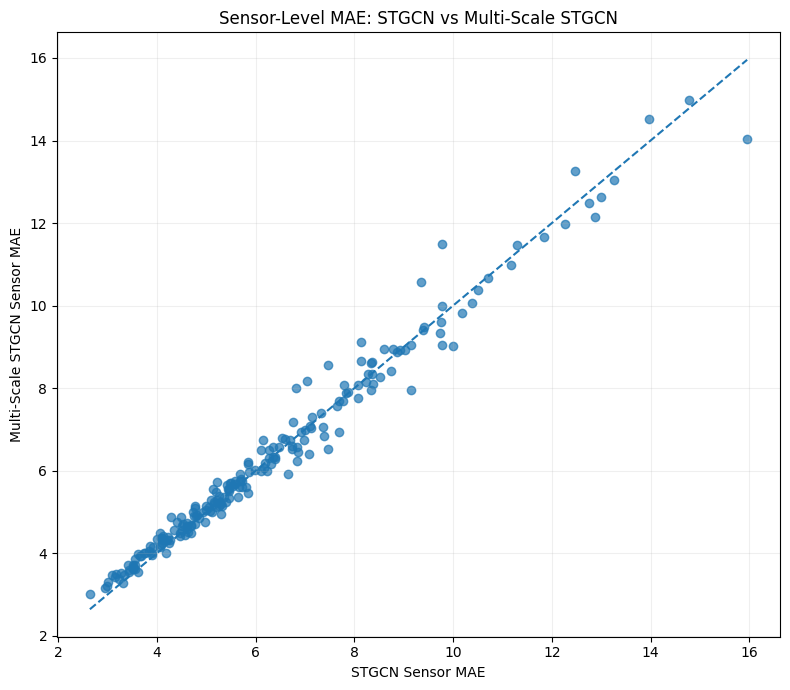


Sensor-level model comparison
--------------------------------
Multi-Scale improved: 78
Multi-Scale degraded: 129
Equal:                0
Total:                207

Step 6 completed.


In [8]:
# ============================================================
# PHASE 9 — ERROR ANALYSIS
# STEP 6 — SENSOR ERROR CORRELATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Sensor-level MAE arrays
# ------------------------------------------------------------

stgcn_sensor_mae = sensor_results["STGCN_MAE"].to_numpy()

proposed_sensor_mae = sensor_results["MultiScale_MAE"].to_numpy()

assert len(stgcn_sensor_mae) == 207
assert len(proposed_sensor_mae) == 207


# ------------------------------------------------------------
# 2. Pearson correlation
# ------------------------------------------------------------

pearson_corr = np.corrcoef(
    stgcn_sensor_mae,
    proposed_sensor_mae
)[0, 1]

print(f"Pearson correlation of sensor-level MAE: {pearson_corr:.6f}")


# ------------------------------------------------------------
# 3. Rank correlation
# ------------------------------------------------------------

stgcn_ranks = (
    pd.Series(stgcn_sensor_mae)
    .rank(method="average")
    .to_numpy()
)

proposed_ranks = (
    pd.Series(proposed_sensor_mae)
    .rank(method="average")
    .to_numpy()
)

spearman_corr = np.corrcoef(
    stgcn_ranks,
    proposed_ranks
)[0, 1]

print(f"Spearman rank correlation: {spearman_corr:.6f}")


# ------------------------------------------------------------
# 4. Per-sensor difference
# ------------------------------------------------------------

sensor_comparison = sensor_results[
    [
        "Sensor",
        "STGCN_MAE",
        "MultiScale_MAE"
    ]
].copy()

sensor_comparison["Difference"] = (
    sensor_comparison["MultiScale_MAE"]
    - sensor_comparison["STGCN_MAE"]
)

sensor_comparison["Absolute_Change"] = (
    np.abs(sensor_comparison["Difference"])
)

sensor_comparison["Relative_Change_Percent"] = (
    sensor_comparison["Difference"]
    / sensor_comparison["STGCN_MAE"]
) * 100


# ------------------------------------------------------------
# 5. Sensors with largest Multi-Scale improvement
# ------------------------------------------------------------

largest_improvements = (
    sensor_comparison
    .sort_values("Difference")
    .head(15)
)

print("\nLargest Multi-Scale improvements:")
display(largest_improvements)


# ------------------------------------------------------------
# 6. Sensors where Multi-Scale degrades most
# ------------------------------------------------------------

largest_degradations = (
    sensor_comparison
    .sort_values("Difference", ascending=False)
    .head(15)
)

print("\nLargest Multi-Scale degradations:")
display(largest_degradations)


# ------------------------------------------------------------
# 7. Save
# ------------------------------------------------------------

sensor_comparison.to_csv(
    ERROR_ANALYSIS_DIR / "sensor_model_comparison.csv",
    index=False
)


# ------------------------------------------------------------
# 8. Scatter plot
# ------------------------------------------------------------

plt.figure(figsize=(8, 7))

plt.scatter(
    stgcn_sensor_mae,
    proposed_sensor_mae,
    alpha=0.7
)

# Reference line y = x
minimum = min(
    stgcn_sensor_mae.min(),
    proposed_sensor_mae.min()
)

maximum = max(
    stgcn_sensor_mae.max(),
    proposed_sensor_mae.max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("STGCN Sensor MAE")
plt.ylabel("Multi-Scale STGCN Sensor MAE")

plt.title(
    "Sensor-Level MAE: STGCN vs Multi-Scale STGCN"
)

plt.grid(alpha=0.2)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "sensor_mae_scatter.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 9. Count sensors improved/degraded
# ------------------------------------------------------------

improved = np.sum(
    sensor_comparison["Difference"] < 0
)

degraded = np.sum(
    sensor_comparison["Difference"] > 0
)

equal = np.sum(
    sensor_comparison["Difference"] == 0
)

print("\nSensor-level model comparison")
print("--------------------------------")
print(f"Multi-Scale improved: {improved}")
print(f"Multi-Scale degraded: {degraded}")
print(f"Equal:                {equal}")
print(f"Total:                {len(sensor_comparison)}")


print("\nStep 6 completed.")

In [9]:
print("Multi-Scale improved:", improved)
print("Multi-Scale degraded:", degraded)
print("Equal:", equal)

Multi-Scale improved: 78
Multi-Scale degraded: 129
Equal: 0


Pearson correlation: Mean traffic vs STGCN MAE = -0.601493
Pearson correlation: Mean traffic vs Multi-Scale MAE = -0.614858
Spearman correlation: Mean traffic vs STGCN MAE = -0.663917
Spearman correlation: Mean traffic vs Multi-Scale MAE = -0.667464


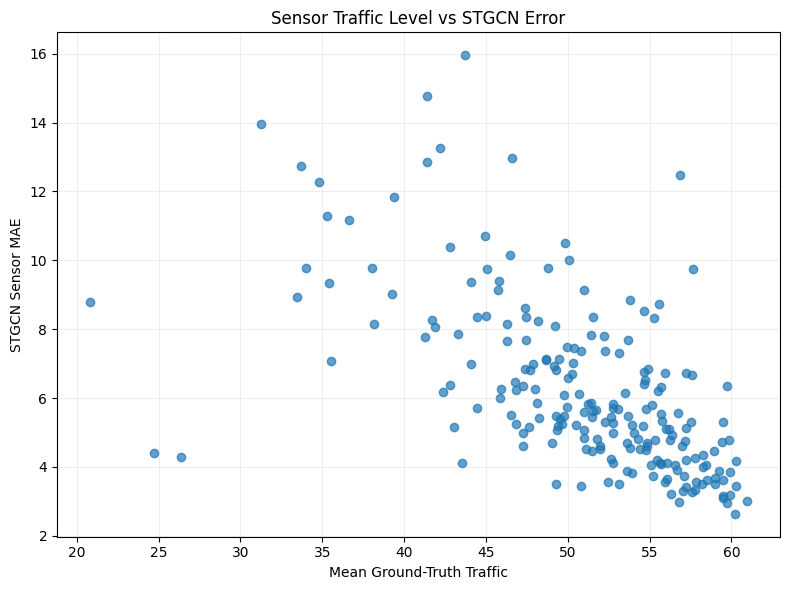

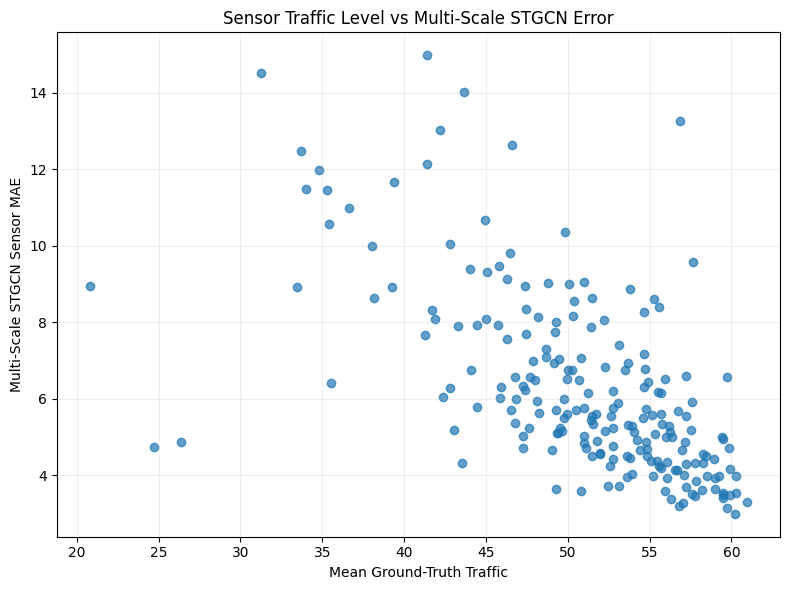


Lowest mean-traffic sensors:


,Sensor,Mean_Traffic,Median_Traffic,STGCN_MAE,MultiScale_MAE,STGCN_RMSE,MultiScale_RMSE
56,56,20.798670,17.285715,8.789856,8.939924,12.326742,12.757139
16,16,24.738407,30.111111,4.393837,4.742604,6.991566,7.852728
196,196,26.351440,32.000000,4.290533,4.869788,6.566947,7.985292
82,82,31.283405,25.250002,13.959284,14.526134,20.608686,21.076622
91,91,33.478672,31.500000,8.923617,8.921442,10.586804,10.527169
12,12,33.708099,20.000000,12.751573,12.477510,15.619600,15.302329
81,81,33.996552,36.777779,9.769874,11.490376,14.334135,16.970013
160,160,34.795383,25.000000,12.268071,11.980418,18.022236,17.612120
144,144,35.287231,32.000000,11.288775,11.469819,13.308639,13.393528
60,60,35.421024,38.500000,9.351792,10.578115,13.343824,15.371745



Highest mean-traffic sensors:


,Sensor,Mean_Traffic,Median_Traffic,STGCN_MAE,MultiScale_MAE,STGCN_RMSE,MultiScale_RMSE
107,107,60.959656,68.000000,3.009915,3.306373,7.819619,7.909925
123,123,60.309517,67.625000,3.431641,3.543596,8.042093,8.080703
99,99,60.302601,67.222221,4.172434,3.990160,8.591630,8.666779
203,203,60.240345,67.625000,2.638431,2.997242,7.615129,7.644889
28,28,59.921593,68.333336,3.863699,4.170741,9.623864,9.586457
44,44,59.908932,67.444443,3.171749,3.496518,7.726068,7.792821
167,167,59.828827,67.250000,4.771990,4.707262,9.350009,9.319996
108,108,59.733124,68.125000,6.346832,6.580750,11.640832,11.274422
45,45,59.704193,66.777779,2.941342,3.153710,7.590783,7.535316
171,171,59.511963,66.333336,3.614561,3.551022,7.930297,7.586125



Step 7 completed.


In [10]:
# ============================================================
# PHASE 9 — ERROR ANALYSIS
# STEP 7 — SENSOR TRAFFIC LEVEL vs SENSOR ERROR
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Average ground-truth traffic per sensor
# ------------------------------------------------------------

# Shape:
# (6841 samples, 3 horizons, 207 sensors)

sensor_mean_traffic = np.mean(
    stgcn_true_original[..., 0],
    axis=(0, 1)
)

sensor_median_traffic = np.median(
    stgcn_true_original[..., 0],
    axis=(0, 1)
)

assert sensor_mean_traffic.shape == (207,)
assert sensor_median_traffic.shape == (207,)


# ------------------------------------------------------------
# 2. Combine traffic and error information
# ------------------------------------------------------------

sensor_traffic_analysis = pd.DataFrame({
    "Sensor": np.arange(207),

    "Mean_Traffic": sensor_mean_traffic,

    "Median_Traffic": sensor_median_traffic,

    "STGCN_MAE": sensor_results["STGCN_MAE"].to_numpy(),

    "MultiScale_MAE": sensor_results["MultiScale_MAE"].to_numpy(),

    "STGCN_RMSE": sensor_results["STGCN_RMSE"].to_numpy(),

    "MultiScale_RMSE": sensor_results["MultiScale_RMSE"].to_numpy(),
})


# ------------------------------------------------------------
# 3. Correlation between traffic level and error
# ------------------------------------------------------------

pearson_stgcn = np.corrcoef(
    sensor_traffic_analysis["Mean_Traffic"],
    sensor_traffic_analysis["STGCN_MAE"]
)[0, 1]

pearson_multiscale = np.corrcoef(
    sensor_traffic_analysis["Mean_Traffic"],
    sensor_traffic_analysis["MultiScale_MAE"]
)[0, 1]

print(
    f"Pearson correlation: Mean traffic vs STGCN MAE = "
    f"{pearson_stgcn:.6f}"
)

print(
    f"Pearson correlation: Mean traffic vs Multi-Scale MAE = "
    f"{pearson_multiscale:.6f}"
)


# ------------------------------------------------------------
# 4. Spearman rank correlation
# ------------------------------------------------------------

traffic_ranks = (
    pd.Series(sensor_mean_traffic)
    .rank(method="average")
    .to_numpy()
)

stgcn_error_ranks = (
    pd.Series(sensor_results["STGCN_MAE"])
    .rank(method="average")
    .to_numpy()
)

multiscale_error_ranks = (
    pd.Series(sensor_results["MultiScale_MAE"])
    .rank(method="average")
    .to_numpy()
)

spearman_stgcn = np.corrcoef(
    traffic_ranks,
    stgcn_error_ranks
)[0, 1]

spearman_multiscale = np.corrcoef(
    traffic_ranks,
    multiscale_error_ranks
)[0, 1]

print(
    f"Spearman correlation: Mean traffic vs STGCN MAE = "
    f"{spearman_stgcn:.6f}"
)

print(
    f"Spearman correlation: Mean traffic vs Multi-Scale MAE = "
    f"{spearman_multiscale:.6f}"
)


# ------------------------------------------------------------
# 5. Save
# ------------------------------------------------------------

sensor_traffic_analysis.to_csv(
    ERROR_ANALYSIS_DIR / "sensor_traffic_vs_error.csv",
    index=False
)


# ------------------------------------------------------------
# 6. Scatter plot — STGCN
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

plt.scatter(
    sensor_traffic_analysis["Mean_Traffic"],
    sensor_traffic_analysis["STGCN_MAE"],
    alpha=0.7
)

plt.xlabel("Mean Ground-Truth Traffic")
plt.ylabel("STGCN Sensor MAE")
plt.title("Sensor Traffic Level vs STGCN Error")

plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "sensor_traffic_vs_stgcn_error.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 7. Scatter plot — Multi-Scale
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

plt.scatter(
    sensor_traffic_analysis["Mean_Traffic"],
    sensor_traffic_analysis["MultiScale_MAE"],
    alpha=0.7
)

plt.xlabel("Mean Ground-Truth Traffic")
plt.ylabel("Multi-Scale STGCN Sensor MAE")
plt.title("Sensor Traffic Level vs Multi-Scale STGCN Error")

plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "sensor_traffic_vs_multiscale_error.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 8. Show lowest/highest traffic sensors
# ------------------------------------------------------------

print("\nLowest mean-traffic sensors:")
display(
    sensor_traffic_analysis
    .sort_values("Mean_Traffic")
    .head(15)
)


print("\nHighest mean-traffic sensors:")
display(
    sensor_traffic_analysis
    .sort_values("Mean_Traffic", ascending=False)
    .head(15)
)


print("\nStep 7 completed.")

In [ ]:
!nvidia-smi

: 